# Chapitre 7 - Cours 1 : ACID, atomicité et durabilité

Ce notebook couvre la première grande section du chapitre, *The Slippery Concept of a
Transaction* : l'introduction du chapitre, *The Meaning of ACID* (*Atomicity*,
*Consistency*, *Isolation*, *Durability*, l'encadré *Replication and Durability*) et
*Single-Object and Multi-Object Operations* (*Single-object writes*, *The need for
multi-object transactions*, *Handling errors and aborts*). Les niveaux d'isolation sont
l'objet des cours 2 à 4 ; la validation atomique distribuée (2PC) sera traitée au
chapitre 9.

**Plan.**

1. Pourquoi des transactions ? Ce qui peut mal tourner.
2. ACID lettre par lettre (et pourquoi le « C » est à part).
3. Atomicité : un journal pour faire « tout ou rien ».
4. Durabilité : fsync, validation groupée et réplication.
5. Opérations sur un objet, opérations sur plusieurs objets.
6. Abandonner et réessayer : une bonne idée, avec des limites.

Le livre ne contient ni code ni exercices : tout ce qui est implémenté ici l'est « à la
main », dans le module [`ddia/transactions.py`](../../ddia/transactions.py).

In [1]:
import os
import sqlite3
import tempfile
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter

from ddia import transactions as tr
from ddia.transactions import R, W, run, plot_history
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
# graduations des axes logarithmiques sans mathtext (la police du style n'a pas le signe moins)
LOGFMT = FuncFormatter(lambda v, _: f"{v:g}")
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)

## 1. Pourquoi des transactions ? (introduction du chapitre)

Une application qui stocke des données doit survivre à une longue liste de mésaventures :
la base ou la machine peut tomber **au milieu d'une écriture**, l'application peut planter
**entre deux opérations**, le réseau peut couper l'application de la base, plusieurs
clients peuvent écrire **en même temps** et s'écraser mutuellement, un client peut lire
des données **à moitié mises à jour**, et les **conditions de course** entre clients
produisent des bogues déroutants.

Traiter chacun de ces cas dans le code applicatif est long et fragile. La **transaction**
regroupe plusieurs lectures et écritures en une unité logique : soit tout est validé
(*commit*), soit tout est annulé (*abort*, *rollback*), et l'application peut alors
réessayer sans crainte. C'est une **abstraction** : la base prend en charge certaines
pannes et certains problèmes de concurrence pour que l'application puisse les ignorer
(ce sont des **garanties de sûreté**).

Le schéma situe les points de défaillance que la transaction neutralise.

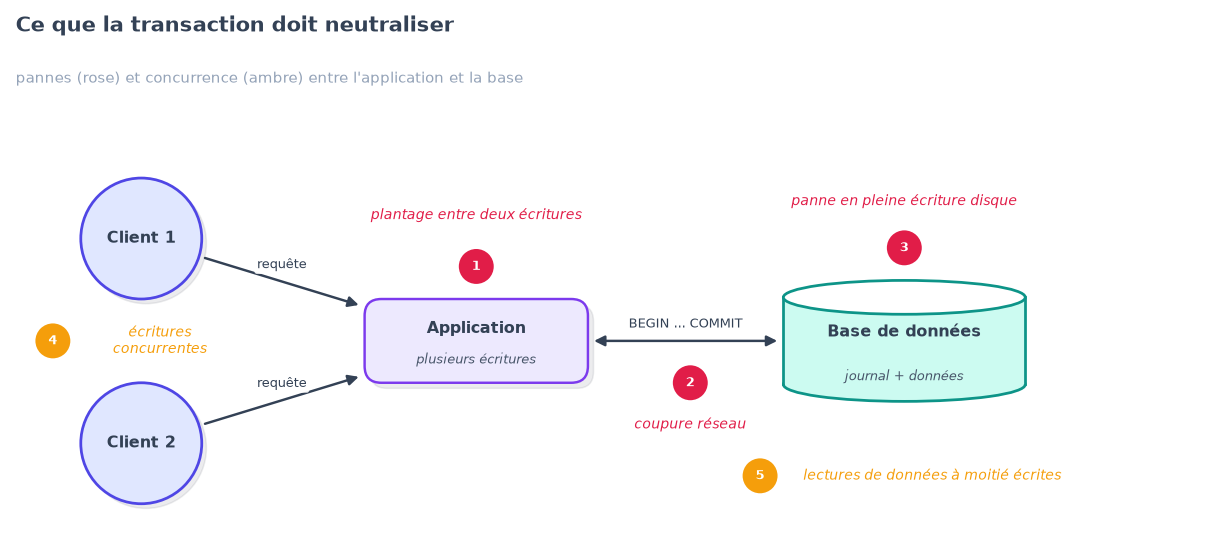

In [2]:
d = Diagram(13, 4.6, title="Ce que la transaction doit neutraliser",
            subtitle="pannes (rose) et concurrence (ambre) entre l'application et la base")
d.box("c1", 1.4, 3.1, "Client 1", kind="user", w=1.3, color=INDIGO)
d.box("c2", 1.4, 0.9, "Client 2", kind="user", w=1.3, color=INDIGO)
d.box("app", 5.0, 2.0, "Application", sub="plusieurs écritures", color=VIOLET, w=2.4)
d.box("db", 9.6, 2.0, "Base de données", sub="journal + données", color=TEAL, kind="db", w=2.6, h=1.3)
d.arrow("c1", "app", "requête")
d.arrow("c2", "app", "requête")
d.arrow("app", "db", "BEGIN ... COMMIT", both=True)
d.badge(5.0, 2.8, "1", color=ROSE)
d.note(5.0, 3.35, "plantage entre deux écritures", color=ROSE)
d.badge(7.3, 1.55, "2", color=ROSE)
d.note(7.3, 1.1, "coupure réseau", color=ROSE)
d.badge(9.6, 3.0, "3", color=ROSE)
d.note(9.6, 3.5, "panne en pleine écriture disque", color=ROSE)
d.badge(0.45, 2.0, "4", color=AMBER)
d.note(1.6, 2.0, "écritures\nconcurrentes", color=AMBER)
d.badge(8.05, 0.55, "5", color=AMBER)
d.note(9.9, 0.55, "lectures de données à moitié écrites", color=AMBER)
d.show()

Les transactions ne sont pas une loi de la nature : elles ont été conçues (System R
d'IBM, 1975) pour **simplifier le modèle de programmation**. Toutes les bases
relationnelles en ont hérité presque à l'identique. À la fin des années 2000, la vague
NoSQL en a souvent fait la première victime (abandon pur et simple, ou mot redéfini pour
désigner des garanties bien plus faibles), d'où l'idée répandue que les transactions
« ne passent pas à l'échelle ».

> **À retenir.** Une transaction transforme une multitude de scénarios d'erreur
> (pannes partielles, concurrence) en un seul : « la transaction a échoué, on peut la
> réessayer ». C'est une abstraction qui a un coût : il faut savoir ce qu'elle garantit
> vraiment, et à quel prix.

## 2. ACID lettre par lettre (section *The Meaning of ACID*)

L'acronyme (Härder et Reuter, 1983) désigne **A**tomicité, **C**ohérence, **I**solation,
**D**urabilité. Le livre prévient : en pratique, l'ACID d'une base n'est pas celui d'une
autre, et le mot est devenu en partie un argument commercial. Son contraire marketing,
BASE (*basically available, soft state, eventual consistency*), est encore plus flou.

| lettre | idée | ce qui se passe sans | qui la garantit |
|---|---|---|---|
| **A**tomicité | une transaction interrompue est **annulée** entièrement : on pourrait dire « abandonnabilité » | écritures partielles, on ne sait pas quoi refaire | la base (journal) |
| **C**ohérence | les **invariants** de l'application restent vrais d'une validation à l'autre | soldes faux, références cassées | surtout l'application (la base n'aide que via les contraintes déclarées) |
| **I**solation | les transactions concurrentes ne se marchent pas dessus ; idéalement **sérialisabilité** | conditions de course | la base (contrôle de concurrence) |
| **D**urabilité | une transaction validée **n'est pas oubliée** | données perdues après une panne | la base (disque, réplication) ; jamais absolue |

Deux pièges de vocabulaire :

- l'**atomicité** ACID n'a rien à voir avec la concurrence (contrairement à une
  opération atomique en programmation multithread) : elle parle de **pannes** ;
- le mot **cohérence** a au moins cinq sens dans le livre : cohérence des répliques
  (chapitre 5), instantané cohérent, hachage cohérent
  (chapitre 6), cohérence au sens CAP, c'est-à-dire linéarisabilité
  (chapitre 9), et cohérence ACID (invariants). Le « C » est une propriété
  de l'application, pas de la base : il dépend de A, I et D, mais aussi de la justesse
  du code.

**L'isolation en une expérience.** Deux clients incrémentent un compteur qui vaut 42 :
chacun lit, ajoute 1, réécrit. Sans isolation suffisante, on obtient 43 au lieu de 44.
Rejouons-le avec le mini-moteur du module : chaque transaction est un **générateur**
Python qui produit des opérations (`R` lecture, `W` écriture) ; l'ordonnanceur les
entrelace selon l'ordre imposé `"ABAB..."`.

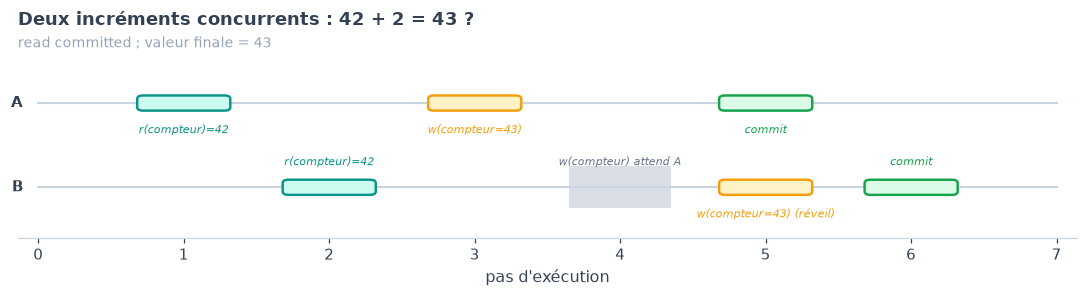

,pas,tx,op,type
0,1,A,r(compteur)=42,read
1,2,B,r(compteur)=42,read
2,3,A,w(compteur=43),write
3,4,B,w(compteur) attend A,wait
4,5,A,commit,commit
5,5,B,w(compteur=43),write
6,6,B,commit,commit


In [3]:
def incremente(cle):
    def prog():
        v = yield R(cle)
        yield W(cle, v + 1)
    return prog


res = run({"compteur": 42}, {"A": incremente("compteur"), "B": incremente("compteur")},
          "ABABAB", level="read_committed")
st = plot_history(res, title="Deux incréments concurrents : 42 + 2 = 43 ?",
                  subtitle=f"read committed ; valeur finale = {res.final['compteur']}", width=10)
st.show()
res.history[["pas", "tx", "op", "type"]]

Chaque ligne est une transaction, chaque colonne un pas d'exécution : lectures en
sarcelle, écritures en ambre, validation en vert, attente de verrou en gris. B lit 42
avant que A n'ait écrit ; son écriture (qui doit attendre que A valide, car A détient le
verrou d'écriture) écrase donc celle de A : c'est la **mise à jour perdue**, que l'on
étudiera au cours 3. En série (A puis B), on aurait 44.

> **À retenir.** A = abandon sûr en cas de panne, C = invariants de l'application,
> I = pas d'interférence entre transactions concurrentes, D = pas d'oubli après
> validation. A, I et D sont des propriétés de la base ; C est surtout l'affaire de
> l'application.

## 3. Atomicité : un journal pour faire « tout ou rien » (sections *Atomicity* et *Single-object writes*)

**Le problème.** Un virement modifie deux comptes. Si la machine tombe entre les deux
écritures, un moteur qui écrit **directement** dans ses données laisse de l'argent
disparaître (ou apparaître).

**La solution classique** : un journal d'écriture anticipée (*write-ahead log*, déjà
rencontré au chapitre 3 pour rendre les B-arbres fiables). On ajoute au
journal les écritures de la transaction, **puis** un enregistrement de validation. Après
une panne, on ne rejoue que les transactions dont l'enregistrement de validation est
présent et intact. Chaque enregistrement porte une **somme de contrôle** (CRC32) pour
détecter une écriture déchirée. Le moment où le record de validation finit d'atteindre
le disque est **le** point de bascule : avant, la transaction peut encore disparaître ;
après, elle est validée.

Voici le journal de trois virements entre trois comptes de 100 € :

In [4]:
init, txs = tr.transfer_txs(3, seed=1)
journal = tr.wal_encode(txs)
print(journal.decode())
print(f"{len(journal)} octets ; solde total initial = {sum(init.values())} €")

1 W A 91 770d5665
1 W C 109 dd60cc9d
1 C - - cb7b546d
2 W A 66 e07ed8ea
2 W B 125 e20df741
2 C - - fa934ef0
3 W B 104 b047b116
3 W C 130 a1670f7c
3 C - - 5ce44544

163 octets ; solde total initial = 300 €


**Expérience exhaustive.** Simulons une panne **à chaque octet** du journal (on ne garde
que le préfixe déjà écrit), puis la récupération. Comparons au moteur naïf qui écrit en
place, avec une panne après chaque écriture.

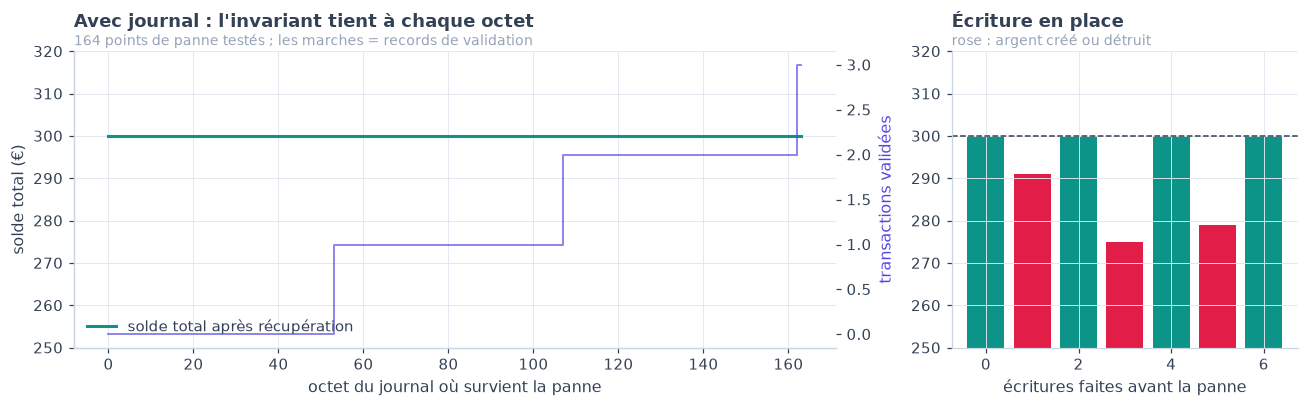

In [5]:
n_ecr = sum(len(w) for _, w in txs)
tot_wal, nb_val = [], []
for b in range(len(journal) + 1):
    etat, valides = tr.wal_recover(init, journal[:b])
    tot_wal.append(sum(etat.values()))
    nb_val.append(len(valides))
tot_naif = [sum(tr.apply_in_place(init, txs, k).values()) for k in range(n_ecr + 1)]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [2.2, 1]})
ax = axes[0]
ax.plot(range(len(journal) + 1), tot_wal, color=TEAL, label="solde total après récupération")
ax2 = ax.twinx()
ax2.step(range(len(journal) + 1), nb_val, color=INDIGO, where="post", lw=1.2, alpha=0.7,
         label="transactions validées")
ax2.set_ylabel("transactions validées", color=INDIGO)
ax2.grid(False)
ax.set_ylim(250, 320)
ax.set_xlabel("octet du journal où survient la panne")
ax.set_ylabel("solde total (€)")
ax.set_title("Avec journal : l'invariant tient à chaque octet")
subtitle(ax, f"{len(journal) + 1} points de panne testés ; les marches = records de validation")
ax.legend(loc="lower left")
ax = axes[1]
ax.bar(range(n_ecr + 1), tot_naif, color=[TEAL if t == 300 else ROSE for t in tot_naif])
ax.axhline(300, color=SLATE, lw=1, ls="--")
ax.set_ylim(250, 320)
ax.set_xlabel("écritures faites avant la panne")
ax.set_title("Écriture en place")
subtitle(ax, "rose : argent créé ou détruit")
finish(fig)
plt.show()

Le journal garantit l'invariant pour chacun des points de panne : le solde total vaut
toujours 300 €. Le nombre de transactions validées n'augmente que lorsque le record `C`
est complet. Le moteur naïf viole l'invariant une fois sur deux (après la première
écriture de chaque virement). Une ligne tronquée est rejetée par la somme de contrôle :
c'est ce qui protège contre un enregistrement « à moitié écrit ».

**Écritures sur un seul objet.** Le même mécanisme protège un objet isolé (le livre prend
un document JSON de 20 ko interrompu à 10 ko) : quasiment tous les moteurs garantissent
atomicité et isolation **par objet**, avec un journal et un verrou par objet. Certains
offrent aussi des opérations atomiques plus riches (incrément, écriture conditionnelle
*compare-and-set*), utiles mais qui ne sont pas des transactions au sens habituel.

> **À retenir.** L'atomicité repose sur un ordre d'écriture : d'abord les données, puis
> le record de validation, chacun protégé par une somme de contrôle. La récupération
> rejoue ce qui est validé et ignore le reste.

## 4. Durabilité : fsync, validation groupée et réplication (section *Durability*)

Une écriture de fichier ordinaire reste d'abord dans le cache du système : une coupure de
courant l'efface. Les bases appellent donc `fsync` avant de confirmer une validation.
Mesurons ce que coûte un `fsync` sur la machine qui a exécuté ce notebook (la valeur
dépend fortement du disque et du système de fichiers).

In [6]:
def mesure_ecritures(n=200, sync=True, taille=128):
    lat = []
    # fichier dans le dossier du notebook (et non dans /tmp, souvent en mémoire)
    with tempfile.NamedTemporaryFile(delete=False, dir=".") as f:
        chemin = f.name
    fd = os.open(chemin, os.O_WRONLY | os.O_APPEND)
    try:
        for _ in range(n):
            t0 = time.perf_counter()
            os.write(fd, b"x" * taille)
            if sync:
                os.fsync(fd)
            lat.append(time.perf_counter() - t0)
    finally:
        os.close(fd)
        os.remove(chemin)
    return np.array(lat) * 1e3

lat_sync, lat_nosync = mesure_ecritures(sync=True), mesure_ecritures(sync=False)
mesures = pd.DataFrame({"écriture + fsync": lat_sync, "écriture seule (cache)": lat_nosync})
mesures.describe(percentiles=[0.5, 0.99]).loc[["mean", "50%", "99%"]].T.rename(
    columns={"mean": "moyenne (ms)", "50%": "médiane (ms)", "99%": "p99 (ms)"})

,moyenne (ms),médiane (ms),p99 (ms)
écriture + fsync,2.761e-01,2.611e-01,0.724
écriture seule (cache),3.350e-04,2.800e-04,0.001


L'écriture qui reste en cache coûte de l'ordre de la microseconde, l'écriture suivie de
`fsync` est des dizaines à des milliers de fois plus lente selon le matériel. Si chaque
validation attend son propre `fsync`, le débit d'un seul flux est borné par
$1/t_{\text{fsync}}$. D'où la **validation groupée** (*group commit*) : les transactions
qui arrivent pendant un `fsync` attendent le suivant et partagent son coût. Avec des
lots de $b$ transactions, le débit devient $b / t_{\text{fsync}}$, au prix d'une latence
un peu plus longue. Le graphique suivant utilise trois ordres de grandeur typiques.

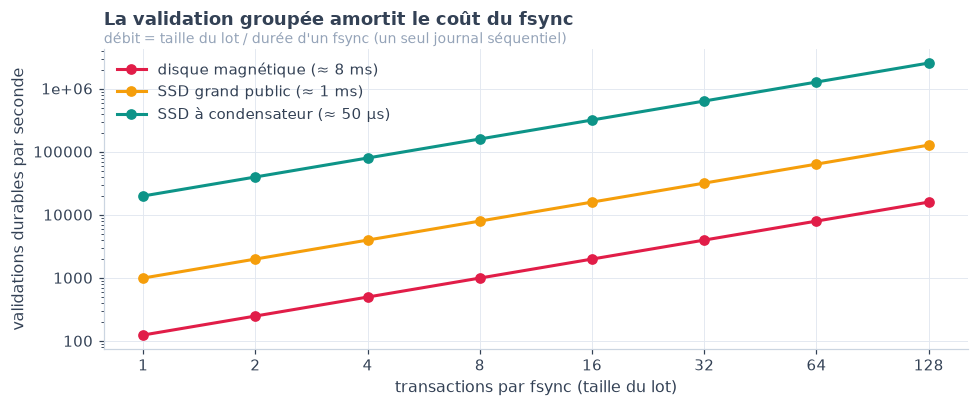

In [7]:
t_fsync = {"disque magnétique (≈ 8 ms)": 8e-3, "SSD grand public (≈ 1 ms)": 1e-3,
           "SSD à condensateur (≈ 50 µs)": 50e-6}
lots = np.array([1, 2, 4, 8, 16, 32, 64, 128])
fig, ax = plt.subplots(figsize=(9, 3.8))
for (nom, t), c in zip(t_fsync.items(), [ROSE, AMBER, TEAL]):
    ax.plot(lots, lots / t, marker="o", color=c, label=nom)
ax.set_xscale("log", base=2); ax.set_yscale("log")
ax.xaxis.set_major_formatter(LOGFMT); ax.yaxis.set_major_formatter(LOGFMT)
ax.set_xlabel("transactions par fsync (taille du lot)")
ax.set_ylabel("validations durables par seconde")
ax.set_title("La validation groupée amortit le coût du fsync")
subtitle(ax, "débit = taille du lot / durée d'un fsync (un seul journal séquentiel)")
ax.legend()
plt.tight_layout(); plt.show()

**Réplication et durabilité (encadré *Replication and Durability*).** Historiquement,
durable voulait dire « écrit sur bande », puis « écrit sur disque », et souvent
aujourd'hui « copié sur plusieurs nœuds ». Aucune solution n'est parfaite : un disque
survit à la panne de sa machine mais reste inaccessible ; des répliques en mémoire
tombent ensemble lors d'une panne **corrélée** (coupure électrique, bogue déclenché par la
même entrée) ; la réplication asynchrone perd les dernières écritures lors d'une bascule ;
les SSD violent parfois leurs garanties lors d'une coupure brutale ; des données peuvent
se corrompre silencieusement et contaminer répliques et sauvegardes récentes.

Un petit calcul illustre l'effet des pannes corrélées. Supposons qu'une réplique perde
ses données avec probabilité $p = 2\,\%$ sur une année, et qu'une fraction $\rho$ des
pertes soit due à un événement commun qui touche toutes les répliques à la fois.

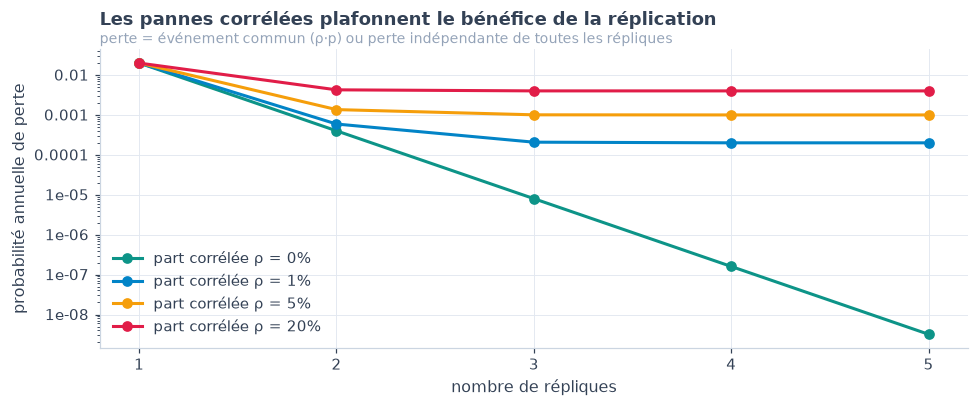

In [8]:
p = 0.02
n_rep = np.arange(1, 6)
fig, ax = plt.subplots(figsize=(9, 3.8))
for rho, c in zip([0.0, 0.01, 0.05, 0.2], [TEAL, SKY, AMBER, ROSE]):
    p_commun = rho * p
    p_indep = (1 - rho) * p
    perte = p_commun + (1 - p_commun) * p_indep ** n_rep
    ax.plot(n_rep, perte, marker="o", color=c, label=f"part corrélée ρ = {rho:.0%}")
ax.set_yscale("log")
ax.yaxis.set_major_formatter(LOGFMT)
ax.set_xticks(n_rep)
ax.set_xlabel("nombre de répliques")
ax.set_ylabel("probabilité annuelle de perte")
ax.set_title("Les pannes corrélées plafonnent le bénéfice de la réplication")
subtitle(ax, "perte = événement commun (ρ·p) ou perte indépendante de toutes les répliques")
ax.legend()
plt.tight_layout(); plt.show()

Avec des pannes indépendantes, chaque réplique divise le risque par 50. Dès que 5 % des
pertes sont corrélées, le risque plafonne vers $\rho p = 10^{-3}$, quel que soit le
nombre de répliques. D'où la recommandation du livre : combiner disque, réplication
**et** sauvegardes (idéalement de nature différente), et prendre les « garanties »
théoriques avec un grain de sel.

> **À retenir.** Durable signifie « écrit sur un support non volatil (fsync) et/ou
> répliqué » avant l'accusé de validation. Le fsync coûte cher, d'où la validation
> groupée ; la réplication aide mais les pannes corrélées bornent son bénéfice. La
> durabilité parfaite n'existe pas.

## 5. Opérations sur un objet, opérations sur plusieurs objets (section *Single-Object and Multi-Object Operations*)

Reprenons l'exemple du livre : une messagerie stocke les courriels **et**, pour éviter un
`COUNT(*)` coûteux, un compteur de messages non lus (une **dénormalisation**). Recevoir un
message = deux écritures qui doivent rester synchronisées. Deux garanties entrent en jeu :

- **isolation** : un lecteur doit voir soit les deux écritures, soit aucune ;
- **atomicité** : si la seconde échoue, la première doit être annulée.

Rejouons d'abord la violation d'isolation : l'expéditeur insère le message puis
incrémente le compteur ; le destinataire lit la boîte et le compteur entre les deux.

In [9]:
def recoit():
    yield W("mail:42", "Bonjour !")
    n = yield R("non_lus")
    yield W("non_lus", n + 1)


def affiche():
    boite = yield tr.S(lambda k, v: k.startswith("mail:"), "liste des mails")
    n = yield R("non_lus")
    return boite, n


for lvl in ["read_uncommitted", "read_committed"]:
    r = run({"non_lus": 0}, {"expéditeur": recoit, "destinataire": affiche},
            ["expéditeur", "destinataire", "destinataire", "expéditeur", "expéditeur"], level=lvl)
    boite, n = r.reads["destinataire"]
    print(f"{tr.LEVEL_LABELS[lvl]:>17} : le destinataire voit {len(boite)} message(s) et un compteur à {n}")

 read uncommitted : le destinataire voit 1 message(s) et un compteur à 0
   read committed : le destinataire voit 0 message(s) et un compteur à 0


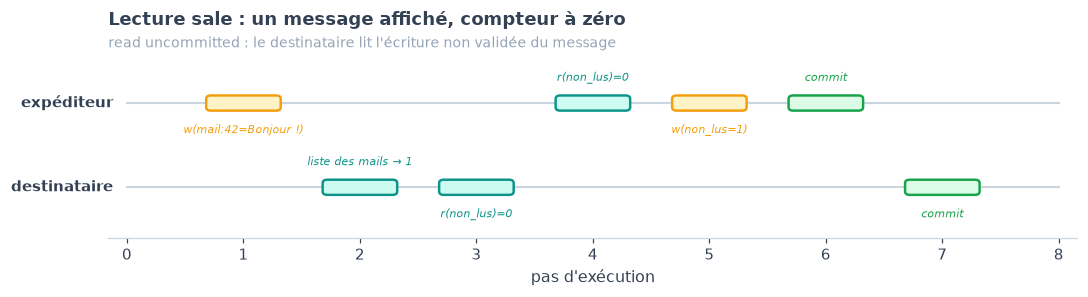

In [10]:
r = run({"non_lus": 0}, {"expéditeur": recoit, "destinataire": affiche},
        ["expéditeur", "destinataire", "destinataire", "expéditeur", "expéditeur"], level="read_uncommitted")
plot_history(r, title="Lecture sale : un message affiché, compteur à zéro",
             subtitle="read uncommitted : le destinataire lit l'écriture non validée du message", width=10).show()

Sous *read uncommitted*, le destinataire voit le message (non encore validé) mais un
compteur à 0 : c'est une **lecture sale** (*dirty read*), étudiée au cours 2. Sous *read
committed*, il ne voit ni l'un ni l'autre : cohérent.

**Atomicité multi-objets avec une vraie base.** SQLite (bibliothèque standard) suffit à
montrer l'annulation : si l'incrément échoue (ici une contrainte `CHECK` violée),
l'insertion du message est annulée avec lui.

In [11]:
con = sqlite3.connect(":memory:", isolation_level=None)
con.executescript("""
CREATE TABLE emails (id INTEGER PRIMARY KEY, dest INTEGER, texte TEXT);
CREATE TABLE compteurs (dest INTEGER PRIMARY KEY, non_lus INTEGER CHECK (non_lus <= 1));
INSERT INTO compteurs VALUES (2, 1);
""")
for atomique in (False, True):
    con.execute("DELETE FROM emails")
    try:
        if atomique:
            con.execute("BEGIN")
        con.execute("INSERT INTO emails (dest, texte) VALUES (2, 'second message')")
        con.execute("UPDATE compteurs SET non_lus = non_lus + 1 WHERE dest = 2")  # viole CHECK
        if atomique:
            con.execute("COMMIT")
    except sqlite3.IntegrityError as e:
        if atomique:
            con.execute("ROLLBACK")
        erreur = str(e)
    n_mails = con.execute("SELECT COUNT(*) FROM emails").fetchone()[0]
    n_cpt = con.execute("SELECT non_lus FROM compteurs").fetchone()[0]
    print(f"{'transaction' if atomique else 'sans transaction':>16} : erreur « {erreur} » -> "
          f"{n_mails} mail(s) stocké(s), compteur = {n_cpt}")

sans transaction : erreur « CHECK constraint failed: non_lus <= 1 » -> 1 mail(s) stocké(s), compteur = 1
     transaction : erreur « CHECK constraint failed: non_lus <= 1 » -> 0 mail(s) stocké(s), compteur = 1


Sans transaction (mode *autocommit*), le message reste stocké alors que le compteur n'a
pas bougé : la dénormalisation est désynchronisée. Avec `BEGIN ... ROLLBACK`, rien ne
reste.

**Qui a besoin de transactions multi-objets ?** Le livre en donne trois cas typiques :
les **clés étrangères** (ou arêtes d'un graphe) qui doivent rester valides ; les données
**dénormalisées** des bases documents sans jointures ; les **index secondaires**, qui sont
des objets distincts à mettre à jour avec la donnée. Sans transaction, on peut s'en sortir,
mais la gestion des erreurs et de la concurrence devient bien plus compliquée. Dans une
base relationnelle, ce qui appartient à une transaction est délimité par `BEGIN` /
`COMMIT` sur une connexion ; beaucoup de bases non relationnelles n'ont pas cette notion
(un *multi-put* peut réussir pour certaines clés et échouer pour d'autres).

> **À retenir.** Les garanties par objet (journal, verrou) sont quasi universelles ; les
> transactions **multi-objets** sont ce qui protège les invariants qui couvrent plusieurs
> lignes, documents ou index.

## 6. Abandonner et réessayer (section *Handling errors and aborts*)

La philosophie ACID : plutôt abandonner la transaction que la laisser à moitié faite. Les
bases à réplication sans leader (chapitre 5) font au contraire « de leur
mieux » sans rien défaire. Et beaucoup d'ORM ne réessaient pas les transactions
abandonnées, ce qui gaspille l'intérêt de l'abandon. Réessayer n'est pourtant pas
anodin : le livre liste cinq pièges.

1. La transaction a **réussi** mais l'accusé s'est perdu : la réessayer l'exécute deux
   fois (il faut une déduplication applicative).
2. Si l'échec vient d'une **surcharge**, réessayer l'aggrave (limiter les réessais,
   attente exponentielle).
3. Inutile de réessayer une erreur **permanente** (contrainte violée).
4. Les **effets de bord** hors base (envoi d'un courriel) ne sont pas annulés.
5. Si le client plante pendant les réessais, ce qu'il voulait écrire est perdu.

Le piège n° 2 se quantifie. Modélisons une base de capacité 1 (unités arbitraires) dont
la probabilité d'échec croît avec la charge $\ell$ : $p(\ell) = \min(1, \ell^4)$
(contention et délais d'attente). Avec des réessais immédiats en nombre illimité, la
charge effective $L$ vérifie $L = \lambda / (1 - p(L))$ : chaque requête est tentée en
moyenne $1/(1-p)$ fois. Avec au plus $k$ tentatives, $L = \lambda (1 - p^k)/(1 - p)$.

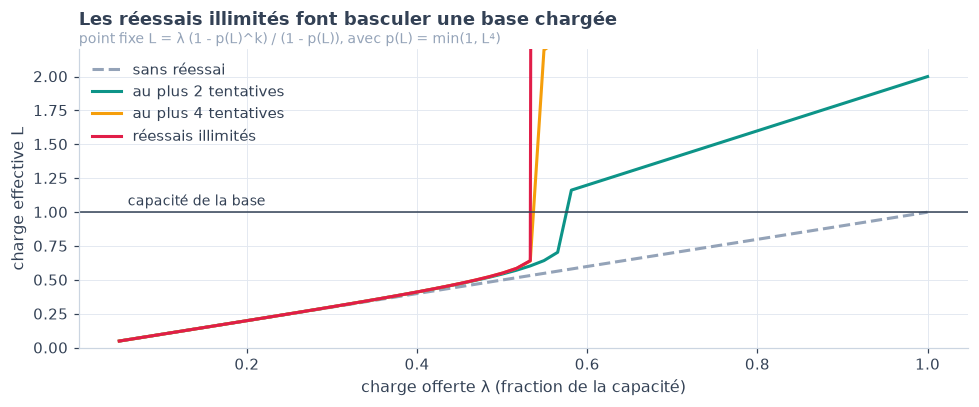

In [12]:
def charge_effective(lam, k=None, iters=400):
    L = lam
    for _ in range(iters):
        p = min(1.0, L ** 4)
        if k is None:
            new = lam / (1 - p) if p < 1 else 50
        else:
            new = lam * (1 - p ** k) / (1 - p) if p < 1 else lam * k
        L = 0.5 * L + 0.5 * min(new, 50)
    return L

lams = np.linspace(0.05, 1.0, 60)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(lams, lams, color=GRAY, ls="--", label="sans réessai")
for k, c in [(2, TEAL), (4, AMBER), (None, ROSE)]:
    ax.plot(lams, [charge_effective(l, k) for l in lams], color=c,
            label="réessais illimités" if k is None else f"au plus {k} tentatives")
ax.axhline(1, color=SLATE, lw=1)
ax.text(0.06, 1.05, "capacité de la base", fontsize=9, color=SLATE)
ax.set_ylim(0, 2.2)
ax.set_xlabel("charge offerte λ (fraction de la capacité)")
ax.set_ylabel("charge effective L")
ax.set_title("Les réessais illimités font basculer une base chargée")
subtitle(ax, "point fixe L = λ (1 - p(L)^k) / (1 - p(L)), avec p(L) = min(1, L⁴)")
ax.legend()
plt.tight_layout(); plt.show()

Tant que la charge est faible, les réessais sont presque gratuits. Vers 55 % de la
capacité, les réessais illimités (et même 4 tentatives) emballent la boucle : la charge
effective franchit la capacité, donc presque tout échoue, donc tout est réessayé... Avec
2 tentatives, la charge reste finie mais double quand tout échoue. C'est la boucle de
rétroaction que le livre recommande de casser en limitant les tentatives et en espaçant
les réessais (attente exponentielle avec gigue), et en traitant les erreurs de surcharge
à part.

> **À retenir.** L'abandon rend le réessai **sûr** pour la base, mais pas forcément pour
> le reste : doublons si l'accusé se perd, effets de bord externes, emballement sous
> charge. Réessayer seulement les erreurs transitoires, en nombre limité, avec attente.